<a href="https://colab.research.google.com/github/vothitrangtho27-sketch/HocMay/blob/main/VoThitrangTho_2001240470_lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***KNN (K-Nearest Neighbors)***

Độ chính xác của mô hình KNN với K=3: 1.00
Ma trận nhầm lẫn:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
Báo cáo phân loại:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



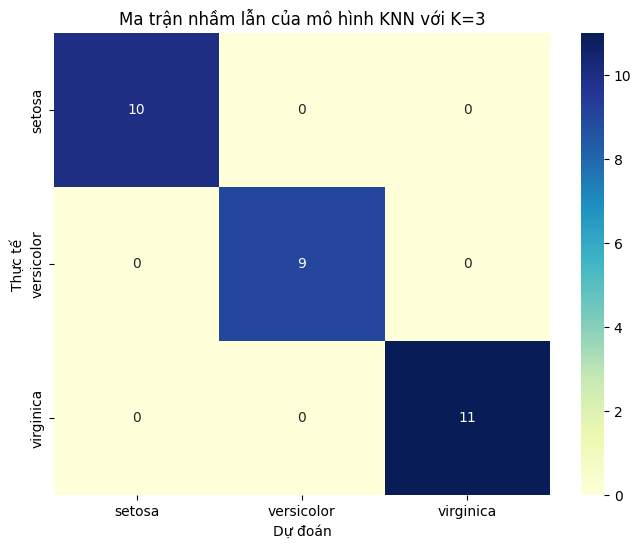

In [32]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
random_state=42)

k = 3
knn_model = KNeighborsClassifier(n_neighbors=k)
knn_model.fit(X_train, y_train)

y_pred = knn_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
print(f"Độ chính xác của mô hình KNN với K={k}: {accuracy:.2f}")
print("Ma trận nhầm lẫn:")
print(conf_matrix)
print("Báo cáo phân loại:")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, cmap="YlGnBu", fmt="d",
xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Dự đoán')
plt.ylabel('Thực tế')
plt.title(f"Ma trận nhầm lẫn của mô hình KNN với K={k}")
plt.show()

# ***SVM (Support Vector Machine)***

Độ chính xác của mô hình SVM: 0.98
Ma trận nhầm lẫn:
[[41  2]
 [ 0 71]]
Báo cáo phân loại:
              precision    recall  f1-score   support

           0       1.00      0.95      0.98        43
           1       0.97      1.00      0.99        71

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



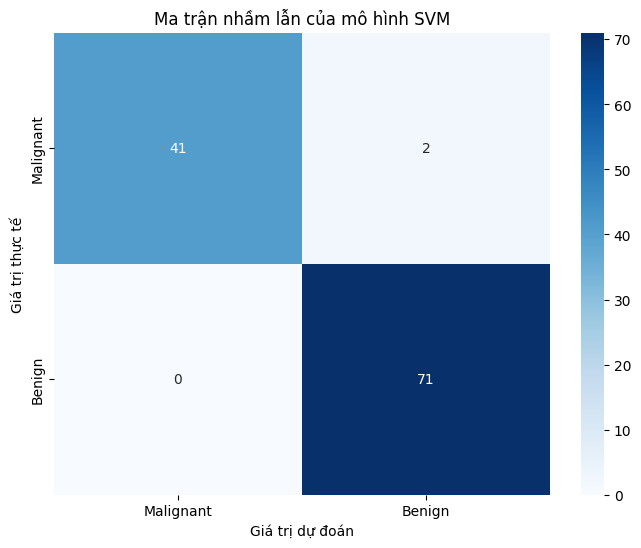

In [33]:
import numpy as np
import pandas as pd
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

cancer = datasets.load_breast_cancer()
X = cancer.data
y = cancer.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

svm_model = SVC(kernel='rbf', C=1, gamma='scale')

svm_model.fit(X_train, y_train)

y_pred = svm_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
print(f"Độ chính xác của mô hình SVM: {accuracy:.2f}")
print("Ma trận nhầm lẫn:")
print(conf_matrix)
print("Báo cáo phân loại:")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
xticklabels=['Malignant', 'Benign'], yticklabels=['Malignant', 'Benign'])

plt.xlabel("Giá trị dự đoán")
plt.ylabel("Giá trị thực tế")
plt.title("Ma trận nhầm lẫn của mô hình SVM")
plt.show()

# ***Bài 1.Thực nghiệm lại code mẫu KNN với các yêu cầu:***

1. Thực nghiệm với các giá trị K khác nhau để tìm ra giá trị K tối ưu

K =  1 | Độ chính xác: 0.9386
K =  2 | Độ chính xác: 0.9386
K =  3 | Độ chính xác: 0.9474
K =  4 | Độ chính xác: 0.9561
K =  5 | Độ chính xác: 0.9474
K =  6 | Độ chính xác: 0.9561
K =  7 | Độ chính xác: 0.9474
K =  8 | Độ chính xác: 0.9561
K =  9 | Độ chính xác: 0.9649
K = 10 | Độ chính xác: 0.9561
K = 11 | Độ chính xác: 0.9561
K = 12 | Độ chính xác: 0.9561
K = 13 | Độ chính xác: 0.9561
K = 14 | Độ chính xác: 0.9561
K = 15 | Độ chính xác: 0.9561

Giá trị K tối ưu nhất là K = 9 với độ chính xác 0.9649


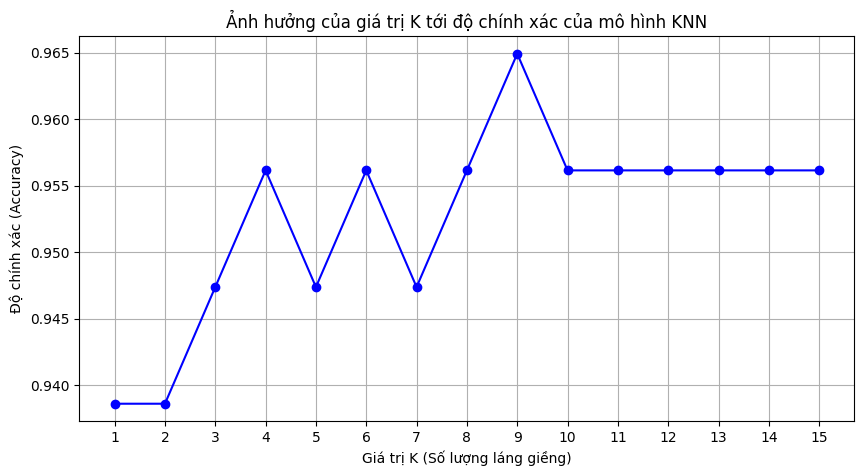

In [34]:
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Thử nghiệm các giá trị K từ 1 đến 15
k_values = list(range(1, 16))
accuracies = []

for k_val in k_values:
    knn = KNeighborsClassifier(n_neighbors=k_val)
    knn.fit(X_train, y_train)
    y_pred_k = knn.predict(X_test)
    acc = accuracy_score(y_test, y_pred_k)
    accuracies.append(acc)
    print(f"K = {k_val:2d} | Độ chính xác: {acc:.4f}")

# Tìm giá trị K tối ưu (lấy K nhỏ nhất nếu có nhiều K cùng đạt độ chính xác cao nhất)
best_acc = max(accuracies)
best_k = k_values[accuracies.index(best_acc)]
print(f"\nGiá trị K tối ưu nhất là K = {best_k} với độ chính xác {best_acc:.4f}")

# Vẽ biểu đồ thể hiện sự ảnh hưởng của K tới độ chính xác
plt.figure(figsize=(10, 5))
plt.plot(k_values, accuracies, marker='o', linestyle='-', color='b')
plt.title('Ảnh hưởng của giá trị K tới độ chính xác của mô hình KNN')
plt.xlabel('Giá trị K (Số lượng láng giềng)')
plt.ylabel('Độ chính xác (Accuracy)')
plt.xticks(k_values)
plt.grid(True)
plt.show()

2. Chuẩn hóa dữ liệu đầu vào để tránh ảnh hưởng của các đặc trưng có đơn vị hoặc phạm
vi khác nhau.

Độ chính xác của mô hình KNN (sau khi chuẩn hóa) với K=3: 1.0000
Ma trận nhầm lẫn:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
Báo cáo phân loại:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



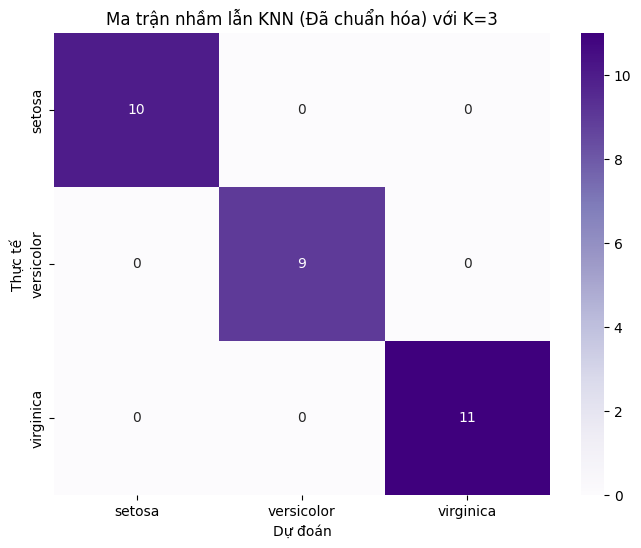

In [35]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tải dữ liệu Iris
iris = load_iris()
X = iris.data
y = iris.target

# 2. Chia tập dữ liệu thành train và test (tỉ lệ 80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Tiến hành chuẩn hóa dữ liệu sử dụng StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Huấn luyện mô hình KNN với K=3 trên dữ liệu đã chuẩn hóa
k = 3
knn_scaled = KNeighborsClassifier(n_neighbors=k)
knn_scaled.fit(X_train_scaled, y_train)

# 5. Dự đoán và đánh giá
y_pred_scaled = knn_scaled.predict(X_test_scaled)
accuracy_scaled = accuracy_score(y_test, y_pred_scaled)
conf_matrix_scaled = confusion_matrix(y_test, y_pred_scaled)

print(f"Độ chính xác của mô hình KNN (sau khi chuẩn hóa) với K={k}: {accuracy_scaled:.4f}")
print("Ma trận nhầm lẫn:")
print(conf_matrix_scaled)
print("Báo cáo phân loại:")
print(classification_report(y_test, y_pred_scaled, target_names=iris.target_names))

# 6. Trực quan hóa ma trận nhầm lẫn
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_scaled, annot=True, cmap="Purples", fmt="d",
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Dự đoán')
plt.ylabel('Thực tế')
plt.title(f"Ma trận nhầm lẫn KNN (Đã chuẩn hóa) với K={k}")
plt.show()

3. Thực nghiệm với các đơn vị tính khoảng cách khác nhau như khoảng cách Manhattan,
Minkowski để xem sự thay đổi trong hiệu quả của mô hình

In [36]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Định nghĩa các độ đo khoảng cách cần thử nghiệm
# Minkowski với p=3 đại diện cho không gian bậc cao hơn
metrics = {
    'Euclidean (L2)': {'metric': 'euclidean', 'p': 2},
    'Manhattan (L1)': {'metric': 'manhattan', 'p': 1},
    'Minkowski (p=3)': {'metric': 'minkowski', 'p': 3}
}

results = []

# Thử nghiệm với các giá trị K khác nhau để có cái nhìn tổng quan
for k_val in [1, 3, 5, 7, 9]:
    for name, params in metrics.items():
        knn = KNeighborsClassifier(n_neighbors=k_val, metric=params['metric'], p=params['p'])
        knn.fit(X_train_scaled, y_train)
        y_pred = knn.predict(X_test_scaled)
        acc = accuracy_score(y_test, y_pred)
        results.append({
            'K': k_val,
            'Độ đo khoảng cách': name,
            'Độ chính xác': acc
        })

# Chuyển kết quả thành DataFrame để dễ quan sát
df_results = pd.DataFrame(results)
display(df_results.pivot(index='K', columns='Độ đo khoảng cách', values='Độ chính xác'))

Độ đo khoảng cách,Euclidean (L2),Manhattan (L1),Minkowski (p=3)
K,,,
1,1.0,0.966667,1.0
3,1.0,1.000000,1.0
5,1.0,1.000000,1.0
7,1.0,1.000000,1.0
9,1.0,1.000000,1.0


### ***Bài 2. Thuật toán KNN với tập dữ liệu giá nhà (Boston Housing)***

<>:11: SyntaxWarning: invalid escape sequence '\s'
<>:11: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1434/699871361.py:11: SyntaxWarning: invalid escape sequence '\s'
  raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)


,K,MSE (Mean Squared Error),R² Score
0,3,19.404281,0.735398
1,5,20.605529,0.719017
2,7,23.415496,0.680700
3,9,24.009424,0.672601


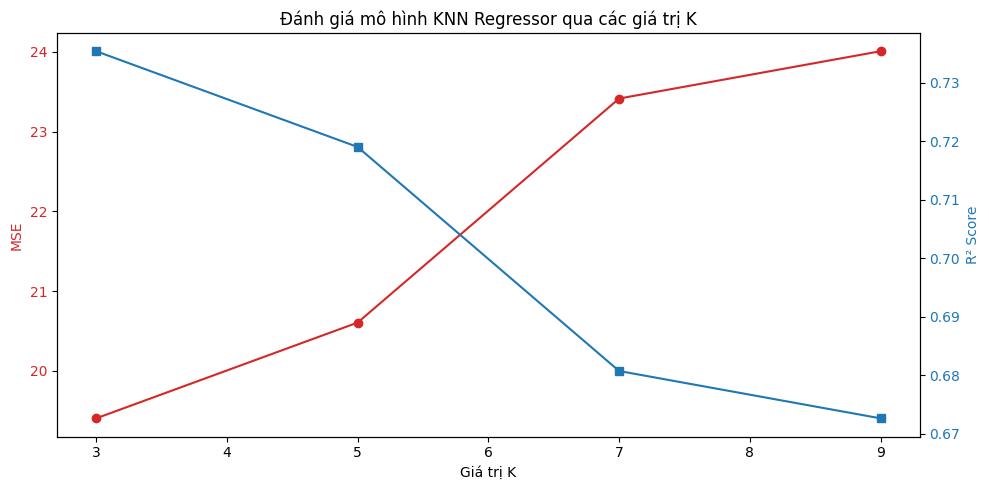

In [37]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# 1. Tải tập dữ liệu Boston Housing từ nguồn trực tuyến chính thức
data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)
data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
target = raw_df.values[1::2, 2]

# 2. Phân chia dữ liệu thành tập huấn luyện và kiểm tra (80:20)
X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.2, random_state=42)

# 3. Chuẩn hóa dữ liệu
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4 & 5. Áp dụng KNN Regressor với các giá trị K khác nhau và đánh giá
k_values = [3, 5, 7, 9]
results_reg = []

for k in k_values:
    knn_reg = KNeighborsRegressor(n_neighbors=k)
    knn_reg.fit(X_train_scaled, y_train)
    y_pred = knn_reg.predict(X_test_scaled)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results_reg.append({
        'K': k,
        'MSE (Mean Squared Error)': mse,
        'R² Score': r2
    })

# Hiển thị bảng kết quả
df_results_reg = pd.DataFrame(results_reg)
display(df_results_reg)

# Trực quan hóa kết quả
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:red'
ax1.set_xlabel('Giá trị K')
ax1.set_ylabel('MSE', color=color)
ax1.plot(k_values, df_results_reg['MSE (Mean Squared Error)'], marker='o', color=color, label='MSE')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('R² Score', color=color)
ax2.plot(k_values, df_results_reg['R² Score'], marker='s', color=color, label='R² Score')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Đánh giá mô hình KNN Regressor qua các giá trị K')
fig.tight_layout()
plt.show()

### ***Bài 3. Thuật toán SVM với tập dữ liệu Iris và thực nghiệm các cách chia dữ liệu***

,Cách chia (Train:Test),Số lượng mẫu Train,Số lượng mẫu Test,Độ chính xác (Accuracy)
0,80:20,120,30,0.966667
1,70:30,105,45,0.933333
2,60:40,90,60,0.950000


/tmp/ipykernel_1434/2651195659.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Cách chia (Train:Test)', y='Độ chính xác (Accuracy)', data=df_svm_results, palette='viridis')


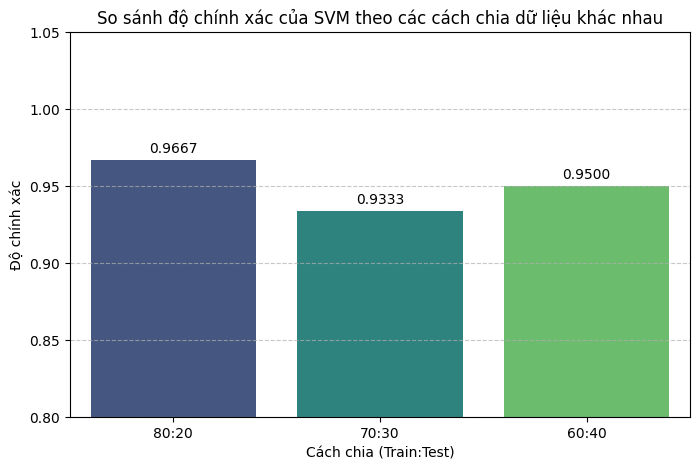

In [38]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tải dữ liệu Iris
iris = load_iris()
X = iris.data
y = iris.target

# 2. Định nghĩa các tỉ lệ chia dữ liệu cần thử nghiệm (train:test)
split_ratios = [
    {'test_size': 0.2, 'label': '80:20'},
    {'test_size': 0.3, 'label': '70:30'},
    {'test_size': 0.4, 'label': '60:40'}
]

svm_results = []

for split in split_ratios:
    # Chia dữ liệu
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=split['test_size'], random_state=42, stratify=y
    )

    # Chuẩn hóa dữ liệu
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Huấn luyện mô hình SVM (Sử dụng cấu hình mặc định rbf kernel)
    svm_model = SVC(kernel='rbf', C=1.0, random_state=42)
    svm_model.fit(X_train_scaled, y_train)

    # Dự đoán và đánh giá
    y_pred = svm_model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)

    svm_results.append({
        'Cách chia (Train:Test)': split['label'],
        'Số lượng mẫu Train': X_train.shape[0],
        'Số lượng mẫu Test': X_test.shape[0],
        'Độ chính xác (Accuracy)': acc
    })

# 3. Hiển thị bảng kết quả so sánh
df_svm_results = pd.DataFrame(svm_results)
display(df_svm_results)

# 4. Trực quan hóa kết quả so sánh độ chính xác
plt.figure(figsize=(8, 5))
sns.barplot(x='Cách chia (Train:Test)', y='Độ chính xác (Accuracy)', data=df_svm_results, palette='viridis')
plt.ylim(0.8, 1.05)
plt.title('So sánh độ chính xác của SVM theo các cách chia dữ liệu khác nhau')
plt.ylabel('Độ chính xác')
for index, row in df_svm_results.iterrows():
    plt.text(index, row['Độ chính xác (Accuracy)'] + 0.005, f"{row['Độ chính xác (Accuracy)']:.4f}", color='black', ha="center")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### ***Bài 4. Thuật toán SVR với tập dữ liệu Boston Housing (Kernel: Linear & RBF)***

<>:12: SyntaxWarning: invalid escape sequence '\s'
<>:12: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1434/4170120156.py:12: SyntaxWarning: invalid escape sequence '\s'
  raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)


,Kernel,MSE (Mean Squared Error),R² Score
0,linear,28.785637,0.607471
1,rbf,12.738192,0.826298


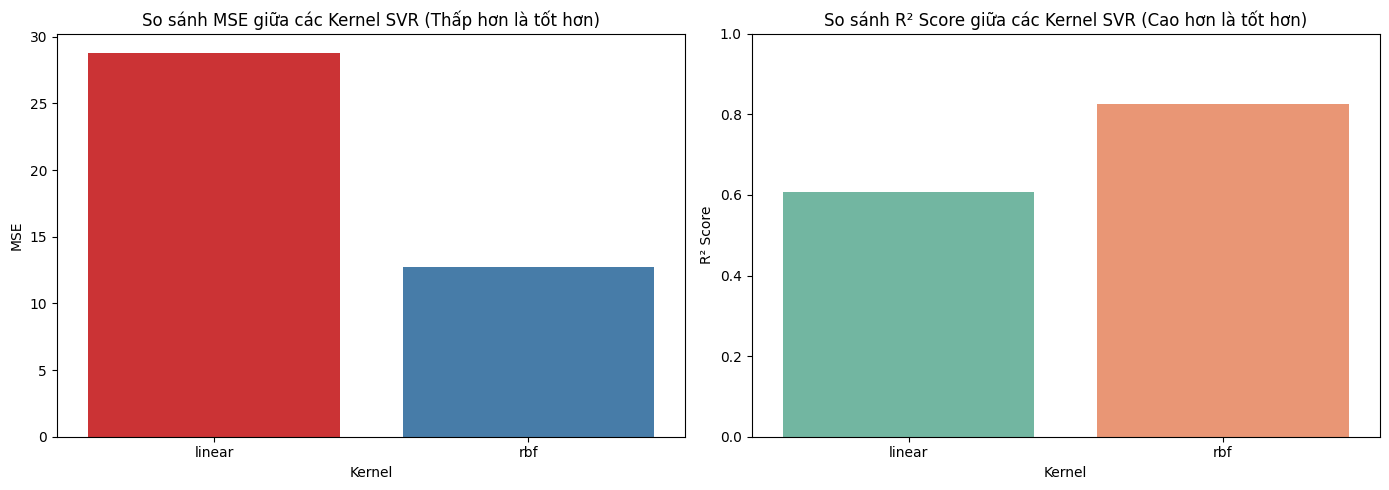

In [39]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tải tập dữ liệu Boston Housing từ nguồn trực tuyến chính thức
data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)
data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
target = raw_df.values[1::2, 2]

# 2. Phân chia dữ liệu thành tập huấn luyện và kiểm tra (80:20)
X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.2, random_state=42)

# 3. Chuẩn hóa dữ liệu
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Áp dụng SVR với kernel linear và rbf
kernels = ['linear', 'rbf']
svr_results = []

for kernel in kernels:
    # Huấn luyện mô hình SVR
    svr_model = SVR(kernel=kernel, C=10.0, epsilon=0.1) # Sử dụng C=10 để tối ưu hóa hiệu năng tốt hơn trên tập dữ liệu này
    svr_model.fit(X_train_scaled, y_train)

    # Dự đoán
    y_pred = svr_model.predict(X_test_scaled)

    # Đánh giá
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    svr_results.append({
        'Kernel': kernel,
        'MSE (Mean Squared Error)': mse,
        'R² Score': r2
    })

# 5. Hiển thị bảng kết quả so sánh
df_svr_results = pd.DataFrame(svr_results)
display(df_svr_results)

# Trực quan hóa so sánh kết quả
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x='Kernel', y='MSE (Mean Squared Error)', data=df_svr_results, ax=ax1, palette='Set1', hue='Kernel', legend=False)
ax1.set_title('So sánh MSE giữa các Kernel SVR (Thấp hơn là tốt hơn)')
ax1.set_ylabel('MSE')

sns.barplot(x='Kernel', y='R² Score', data=df_svr_results, ax=ax2, palette='Set2', hue='Kernel', legend=False)
ax2.set_title('So sánh R² Score giữa các Kernel SVR (Cao hơn là tốt hơn)')
ax2.set_ylabel('R² Score')
ax2.set_ylim(0, 1.0)

plt.tight_layout()
plt.show()

### ***Phần 2: Bài Tập Thực Hành Nâng Cao***

#### **Bài 1. Thực nghiệm các loại Kernel khác nhau của SVM**
Chúng ta sẽ thử nghiệm các loại kernel khác nhau của SVM (`linear`, `poly`, `rbf`, `sigmoid`) trên tập dữ liệu Breast Cancer và đánh giá hiệu suất của mỗi loại.

,Kernel,Độ chính xác (Accuracy)
0,linear,0.956140
1,poly,0.868421
2,rbf,0.982456
3,sigmoid,0.956140


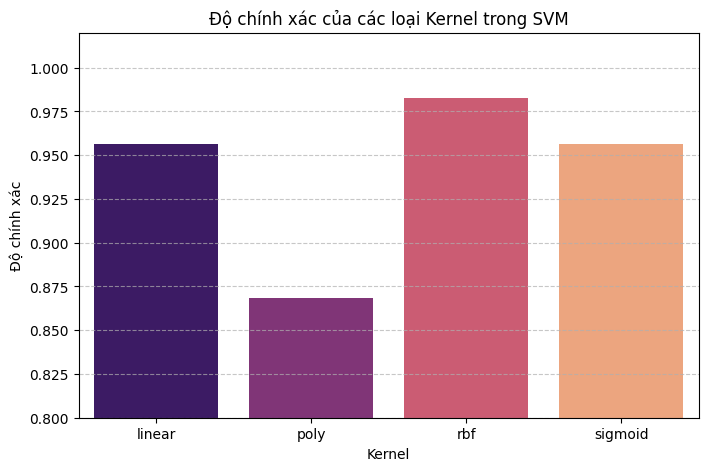

In [40]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tải dữ liệu
cancer = load_breast_cancer()
X, y = cancer.data, cancer.target

# 2. Chia tập dữ liệu (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Chuẩn hóa dữ liệu
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Thực nghiệm các kernel khác nhau
kernels = ['linear', 'poly', 'rbf', 'sigmoid']
kernel_results = []

for knl in kernels:
    model = SVC(kernel=knl, C=1.0, random_state=42)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    kernel_results.append({'Kernel': knl, 'Độ chính xác (Accuracy)': acc})

df_kernels = pd.DataFrame(kernel_results)
display(df_kernels)

# Trực quan hóa
plt.figure(figsize=(8, 5))
sns.barplot(x='Kernel', y='Độ chính xác (Accuracy)', data=df_kernels, palette='magma', hue='Kernel', legend=False)
plt.ylim(0.8, 1.02)
plt.title('Độ chính xác của các loại Kernel trong SVM')
plt.ylabel('Độ chính xác')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

#### **Bài 2. Sử dụng GridSearchCV tìm siêu tham số tối ưu cho SVM**
Tối ưu hóa mô hình SVM bằng cách duyệt qua không gian tham số của $C$, $\gamma$ và `kernel` sử dụng bộ công cụ `GridSearchCV` từ scikit-learn.

In [41]:
from sklearn.model_selection import GridSearchCV

# Định nghĩa lưới tham số cần tìm kiếm
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.01, 0.1, 1],
    'kernel': ['rbf', 'linear']
}

# Khởi tạo GridSearchCV
grid_search = GridSearchCV(SVC(random_state=42), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)

# Kết quả tham số tốt nhất
print("Siêu tham số tối ưu nhất tìm thấy:")
print(grid_search.best_params_)
print(f"Độ chính xác trung bình tốt nhất trên tập Validation: {grid_search.best_score_:.4f}")

# Đánh giá cấu hình tốt nhất trên tập Test
best_model = grid_search.best_estimator_
y_test_pred = best_model.predict(X_test_scaled)
test_acc = accuracy_score(y_test, y_test_pred)
print(f"Độ chính xác thực tế trên tập kiểm tra (Test): {test_acc:.4f}")

Siêu tham số tối ưu nhất tìm thấy:
{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
Độ chính xác trung bình tốt nhất trên tập Validation: 0.9758
Độ chính xác thực tế trên tập kiểm tra (Test): 0.9825


#### **Bài 3. So sánh KNN và SVM với tập dữ liệu chữ số viết tay (Digits Dataset)**
Áp dụng KNN và SVM (kernel poly & rbf) để phân loại chữ số viết tay 8x8 pixels.

=== Kết quả của KNN (K=5) ===
Độ chính xác: 0.9639
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.92      1.00      0.96        36
           2       0.95      1.00      0.97        35
           3       1.00      0.97      0.99        37
           4       0.97      0.94      0.96        36
           5       0.97      0.97      0.97        37
           6       0.97      1.00      0.99        36
           7       0.92      0.97      0.95        36
           8       0.97      0.89      0.93        35
           9       0.97      0.89      0.93        36

    accuracy                           0.96       360
   macro avg       0.96      0.96      0.96       360
weighted avg       0.96      0.96      0.96       360

--------------------------------------------------
=== Kết quả của SVM (Poly Kernel) ===
Độ chính xác: 0.9722
              precision    recall  f1-score   support

           0       1.00  

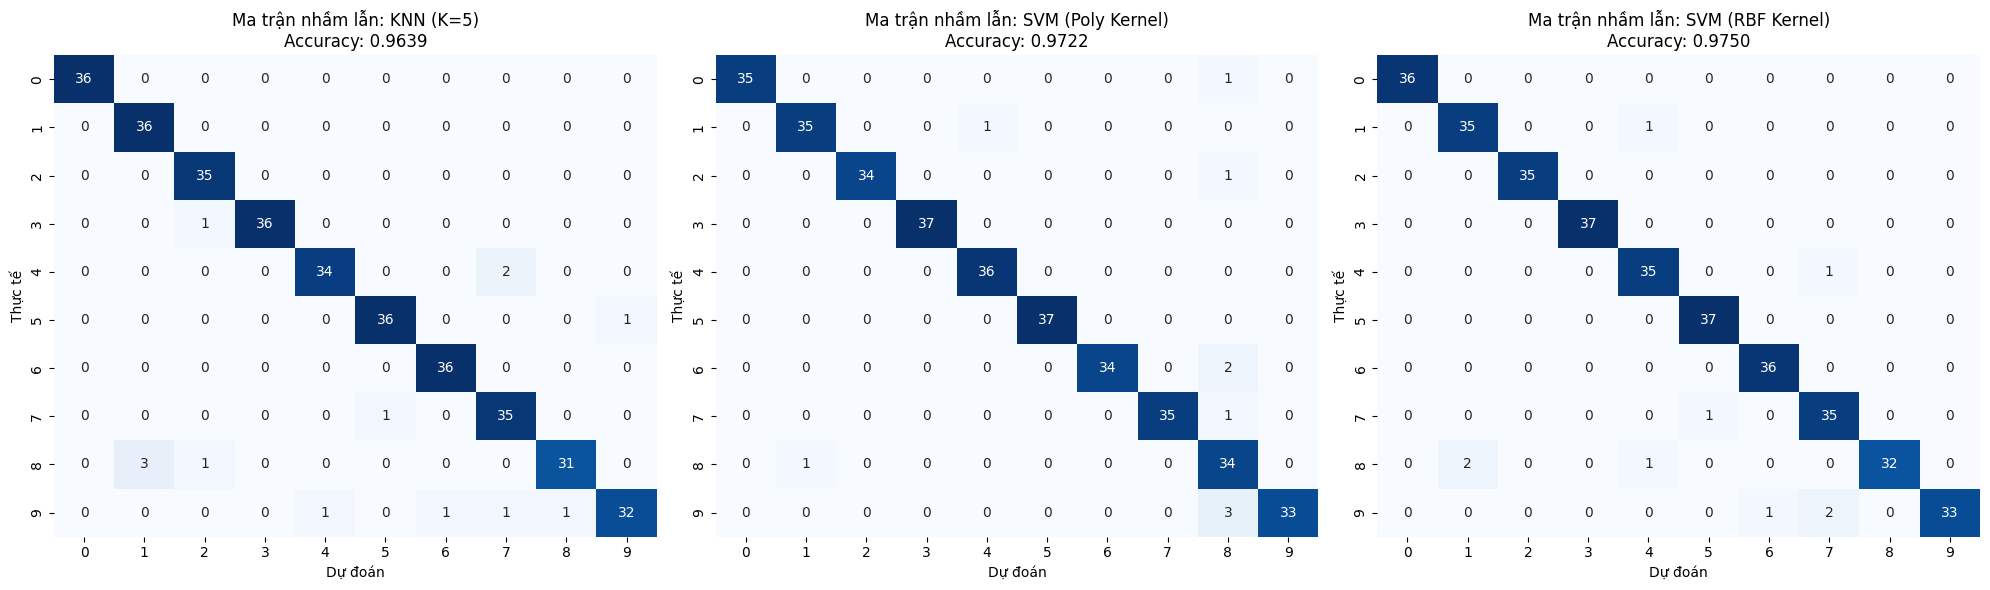

In [42]:
from sklearn.datasets import load_digits
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report

# 1. Tải tập dữ liệu Digits
digits = load_digits()
X_dig, y_dig = digits.data, digits.target

# 2. Phân chia dữ liệu (80:20)
X_train_dig, X_test_dig, y_train_dig, y_test_dig = train_test_split(
    X_dig, y_dig, test_size=0.2, random_state=42, stratify=y_dig
)

# Chuẩn hóa dữ liệu
scaler_dig = StandardScaler()
X_train_dig_scaled = scaler_dig.fit_transform(X_train_dig)
X_test_dig_scaled = scaler_dig.transform(X_test_dig)

# 3. Định nghĩa các mô hình thử nghiệm
models_dig = {
    'KNN (K=5)': KNeighborsClassifier(n_neighbors=5),
    'SVM (Poly Kernel)': SVC(kernel='poly', degree=3, C=1.0, random_state=42),
    'SVM (RBF Kernel)': SVC(kernel='rbf', C=1.0, random_state=42)
}

# Huấn luyện và đánh giá từng mô hình
dig_results = {}

for name, model in models_dig.items():
    # Sử dụng dữ liệu đã chuẩn hóa cho cả KNN và SVM
    model.fit(X_train_dig_scaled, y_train_dig)
    y_pred_dig = model.predict(X_test_dig_scaled)

    acc = accuracy_score(y_test_dig, y_pred_dig)
    cm = confusion_matrix(y_test_dig, y_pred_dig)
    dig_results[name] = {'accuracy': acc, 'confusion_matrix': cm, 'predictions': y_pred_dig}

    print(f"=== Kết quả của {name} ===")
    print(f"Độ chính xác: {acc:.4f}")
    print(classification_report(y_test_dig, y_pred_dig))
    print("-" * 50)

# 4. Trực quan hóa ma trận nhầm lẫn của các mô hình
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for idx, (name, res) in enumerate(dig_results.items()):
    sns.heatmap(res['confusion_matrix'], annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(f"Ma trận nhầm lẫn: {name}\nAccuracy: {res['accuracy']:.4f}")
    axes[idx].set_xlabel('Dự đoán')
    axes[idx].set_ylabel('Thực tế')

plt.tight_layout()
plt.show()

### ***Bài 1 Tổng hợp: Thực nghiệm KNN với Chuẩn hóa, tối ưu K và đa dạng hóa khoảng cách***

Độ đo,Euclidean (L2),Manhattan (L1),Minkowski (p=3)
K,,,
1,0.966667,0.966667,0.966667
2,0.933333,0.933333,0.900000
3,0.933333,0.966667,0.933333
4,0.933333,0.900000,0.933333
5,0.933333,0.933333,0.933333
6,0.933333,0.933333,0.933333
7,0.966667,0.966667,0.966667
8,0.933333,0.966667,0.933333
9,0.966667,0.933333,0.966667



Cấu hình tối ưu nhất: K = 11 sử dụng khoảng cách Minkowski (p=3) đạt độ chính xác 1.0000


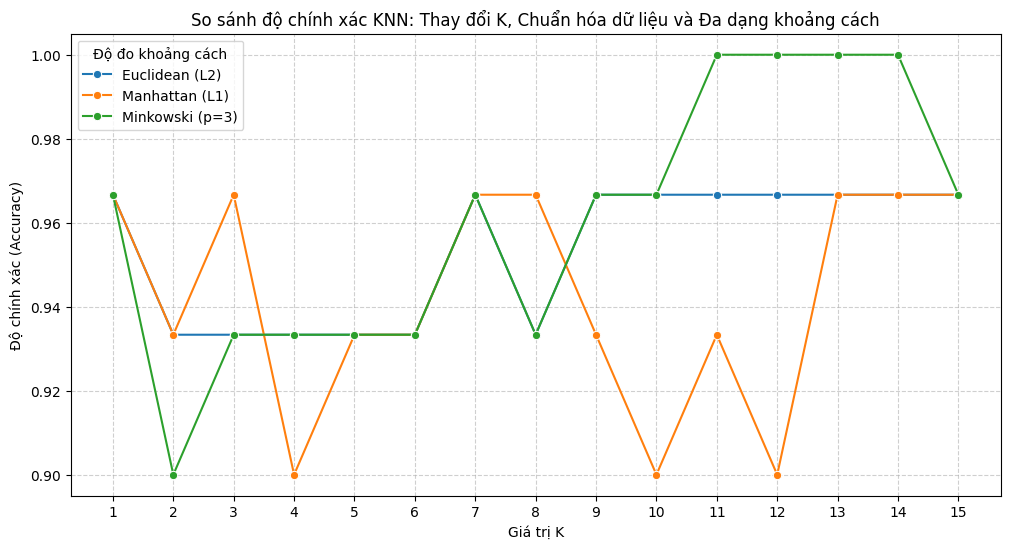

In [43]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tải và chuẩn bị dữ liệu Iris
iris = load_iris()
X, y = iris.data, iris.target

# Phân chia train/test (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 2. Chuẩn hóa đặc trưng đầu vào
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Thực nghiệm tích hợp: Duyệt qua các giá trị K và các độ đo khoảng cách khác nhau
k_values = list(range(1, 16))
metrics = {
    'Euclidean (L2)': {'metric': 'euclidean', 'p': 2},
    'Manhattan (L1)': {'metric': 'manhattan', 'p': 1},
    'Minkowski (p=3)': {'metric': 'minkowski', 'p': 3}
}

full_results = []

for k in k_values:
    for name, params in metrics.items():
        knn = KNeighborsClassifier(n_neighbors=k, metric=params['metric'], p=params['p'])
        knn.fit(X_train_scaled, y_train)
        y_pred = knn.predict(X_test_scaled)
        acc = accuracy_score(y_test, y_pred)
        full_results.append({
            'K': k,
            'Độ đo': name,
            'Độ chính xác (Accuracy)': acc
        })

# Biến đổi dữ liệu sang dạng bảng pivot để dễ phân tích
df_full_results = pd.DataFrame(full_results)
df_pivot = df_full_results.pivot(index='K', columns='Độ đo', values='Độ chính xác (Accuracy)')
display(df_pivot)

# Tìm cấu hình tối ưu nhất
best_idx = df_full_results['Độ chính xác (Accuracy)'].idxmax()
best_config = df_full_results.loc[best_idx]
print(f"\nCấu hình tối ưu nhất: K = {best_config['K']} sử dụng khoảng cách {best_config['Độ đo']} đạt độ chính xác {best_config['Độ chính xác (Accuracy)']:.4f}")

# Vẽ đồ thị biểu diễn kết quả so sánh
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_full_results, x='K', y='Độ chính xác (Accuracy)', hue='Độ đo', marker='o')
plt.title('So sánh độ chính xác KNN: Thay đổi K, Chuẩn hóa dữ liệu và Đa dạng khoảng cách')
plt.xlabel('Giá trị K')
plt.ylabel('Độ chính xác (Accuracy)')
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Độ đo khoảng cách')
plt.show()